# KNN

**Goal:** predict whether a new student will **Pass** or **Fail**, using:
- `hours_studied` (per day)
- `previous_score` (last exam, out of 100)

**KNN idea:** to predict a new student, find the **K most similar students** we already know and let them **vote**.

Every line of code below has a comment (the text after `#`) that explains what it does. Python ignores comments; they are just notes for humans.

## 1. Import libraries

In [ ]:
import numpy as np  # numpy: a library for fast math on numbers and arrays
import pandas as pd  # pandas: a library for working with tables of data
import matplotlib.pyplot as plt  # matplotlib: a library for drawing charts
from collections import Counter  # Counter: counts how many times each item appears

## 2. Our small dataset
22 students whose results we already know.

In [ ]:
data = {  # start a dictionary (name -> list of values) that holds our table
    'hours_studied':  [1, 2, 2, 3, 3, 1, 4, 2, 3, 5, 5,  # hours studied by the students
                       5, 6, 7, 6, 8, 7, 9, 5, 8, 6, 4],
    'previous_score': [40, 45, 55, 50, 60, 60, 45, 35, 40, 45, 65,  # previous scores of the first students
                       65, 70, 60, 80, 75, 85, 90, 75, 65, 60, 70],
    'result':         ['Fail']*10 + ['Pass']*12  # first 10 students failed, the next 12 passed
}

df = pd.DataFrame(data)  # turn the dictionary into a pandas table (DataFrame)
print(df.shape)  # print (number of rows, number of columns)
df.head(10)  # show the first 10 rows of the table

(22, 3)


,hours_studied,previous_score,result
0,1,40,Fail
1,2,45,Fail
2,2,55,Fail
3,3,50,Fail
4,3,60,Fail
5,1,60,Fail
6,4,45,Fail
7,2,35,Fail
8,3,40,Fail
9,5,45,Fail


## 3. Look at the data
Each dot is a student. Green = Pass, red = Fail.

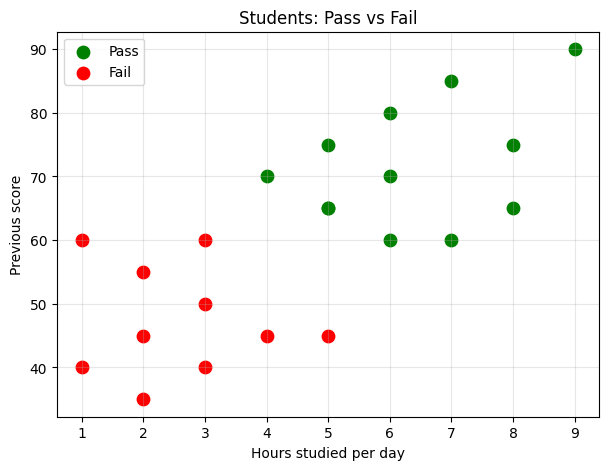

In [ ]:
def plot_students(new_students=None):  # define a function that draws the chart
    plt.figure(figsize=(7, 5))  # create an empty chart, 7 inches wide and 5 inches tall
    for label, color in [('Pass', 'green'), ('Fail', 'red')]:  # repeat once for Pass (green) and once for Fail (red)
        subset = df[df['result'] == label]  # keep only the rows whose result matches this label
        plt.scatter(subset['hours_studied'], subset['previous_score'],  # draw dots: hours on x-axis, score on y-axis
                    c=color, s=80, label=label)  # set the dot color, dot size, and legend name
    if new_students is not None:  # only do the next lines if we were given new students
        plt.scatter(new_students[:, 0], new_students[:, 1],  # draw the new students using their hours and scores
                    c='blue', marker='*', s=300, label='New student')  # blue big stars so they stand out
    plt.xlabel('Hours studied per day')  # text label under the x-axis
    plt.ylabel('Previous score')  # text label beside the y-axis
    plt.title('Students: Pass vs Fail')  # title at the top of the chart
    plt.legend()  # show the box explaining the colors
    plt.grid(True, alpha=0.3)  # add light grid lines to make reading easier
    plt.show()  # display the finished chart

plot_students()  # call the function to draw the chart (no new students yet)

## 4. Prepare the data

- **X** = the features (hours, score)
- **y** = the answer we want to predict (Pass/Fail)

**Scaling:** hours go from 1 to 9 but scores go from 35 to 90. Scores would dominate the distance just because their numbers are bigger. So we squeeze both into a 0-to-1 range (*min-max scaling*) to make them fair.

In [ ]:
X = df[['hours_studied', 'previous_score']].values  # take the two feature columns as a numpy array
y = df['result'].values  # take the result column (Pass/Fail) as a numpy array

X_min = X.min(axis=0)  # smallest value in each column (hours and score)
X_max = X.max(axis=0)  # largest value in each column (hours and score)

def scale(values):  # define a function that converts raw numbers into 0-to-1 numbers
    return (values - X_min) / (X_max - X_min)  # formula: (value - min) / (max - min)

X_scaled = scale(X)  # scale all of our known students
print('First 3 students (scaled):')  # print a heading
print(X_scaled[:7].round(2))  # print the first 3 scaled students, rounded to 2 decimals

First 3 students (scaled):
[[0.   0.09]
 [0.12 0.18]
 [0.12 0.36]
 [0.25 0.27]
 [0.25 0.45]
 [0.   0.45]
 [0.38 0.18]]


## 5. KNN from scratch

Three steps:
1. **Measure distance** from the new student to every known student
2. **Pick the K closest** students
3. **Vote:** the most common result among them wins

We use *Euclidean distance* (straight-line distance, like a ruler).

In [ ]:
def euclidean_distance(a, b):  # define a function that measures the distance between two points a and b
    return np.sqrt(np.sum((a - b) ** 2))  # subtract, square, add up, then square root (Pythagoras)

def knn_predict(new_point, X_train, y_train, k=3, verbose=True):  # define KNN; verbose=True means "print the details"

    # Step 1: distance to every known student
    distances = [euclidean_distance(new_point, x) for x in X_train]  # measure distance from the new student to each known student

    # Step 2: find the k closest students
    nearest_idx = np.argsort(distances)[:k]  # sort distances smallest-first and keep the row numbers of the first k
    nearest_labels = y_train[nearest_idx]  # look up the results (Pass/Fail) of those k neighbors

    # Step 3: majority vote
    prediction = Counter(nearest_labels).most_common(1)[0][0]  # count the results and pick the most common one

    if verbose:  # only print details if verbose is True
        print(f'   The {k} nearest students are:')  # print a heading for the neighbors
        for i in nearest_idx:  # go through each neighbor's row number one by one
            print(f'     Row {i}: distance = {distances[i]:.3f}, result = {y_train[i]}')  # print its distance and its result
        print(f'   Votes: {dict(Counter(nearest_labels))}')  # print how many Pass and Fail votes there were
        print(f'   Prediction: {prediction}')  # print the winning result

    return prediction  # hand the prediction back so other code can use it too

## 6. Predict for new students
We don't know these students' results yet, so let's ask KNN.

In [ ]:
new_students = np.array([  # create a table of 4 new students: [hours, previous score]
    [2, 40],  # studies little, low previous score
    [8, 85],  # studies a lot, high previous score
    [4, 55],  # somewhere in the middle
    [6, 50],  # studies a lot but lower previous score
])  # end of the table

k = 3  # how many neighbors will vote

for i, student in enumerate(new_students, start=1):  # go through each new student, counting from 1
    print(f'Student {i}: {student[0]} hrs, score {student[1]}')  # print who we are predicting for
    knn_predict(scale(student), X_scaled, y, k=k)  # scale the student, then run KNN (it prints the details)
    print()  # print an empty line to separate students

Student 1: 2 hrs, score 40
   The 3 nearest students are:
     Row 1: distance = 0.091, result = Fail
     Row 7: distance = 0.091, result = Fail
     Row 0: distance = 0.125, result = Fail
   Votes: {'Fail': 3}
   Prediction: Fail

Student 2: 8 hrs, score 85
   The 3 nearest students are:
     Row 16: distance = 0.125, result = Pass
     Row 17: distance = 0.155, result = Pass
     Row 15: distance = 0.182, result = Pass
   Votes: {'Pass': 3}
   Prediction: Pass

Student 3: 4 hrs, score 55
   The 3 nearest students are:
     Row 4: distance = 0.155, result = Fail
     Row 3: distance = 0.155, result = Fail
     Row 6: distance = 0.182, result = Fail
   Votes: {'Fail': 3}
   Prediction: Fail

Student 4: 6 hrs, score 50
   The 3 nearest students are:
     Row 9: distance = 0.155, result = Fail
     Row 20: distance = 0.182, result = Pass
     Row 13: distance = 0.221, result = Pass
   Votes: {'Fail': 1, 'Pass': 2}
   Prediction: Pass



## 7. What happens if we change K?

- **Small K** (like 1): very sensitive; one odd neighbor can change the answer.
- **Large K**: smoother, but may ignore local patterns.

In [ ]:
borderline = np.array([5, 55])  # a student right between the Pass and Fail groups

for k in [1, 3, 5, 7, 11]:  # try several different values of K
    print(f'--- K = {k} ---')  # print a heading for this K
    knn_predict(scale(borderline), X_scaled, y, k=k)  # run KNN with this K (it prints the details)
    print()  # print an empty line between runs

--- K = 1 ---
   The 1 nearest students are:
     Row 20: distance = 0.155, result = Pass
   Votes: {'Pass': 1}
   Prediction: Pass

--- K = 3 ---
   The 3 nearest students are:
     Row 20: distance = 0.155, result = Pass
     Row 10: distance = 0.182, result = Pass
     Row 11: distance = 0.182, result = Pass
   Votes: {'Pass': 3}
   Prediction: Pass

--- K = 5 ---
   The 5 nearest students are:
     Row 20: distance = 0.155, result = Pass
     Row 10: distance = 0.182, result = Pass
     Row 11: distance = 0.182, result = Pass
     Row 9: distance = 0.182, result = Fail
     Row 6: distance = 0.221, result = Fail
   Votes: {'Pass': 3, 'Fail': 2}
   Prediction: Pass

--- K = 7 ---
   The 7 nearest students are:
     Row 20: distance = 0.155, result = Pass
     Row 10: distance = 0.182, result = Pass
     Row 11: distance = 0.182, result = Pass
     Row 9: distance = 0.182, result = Fail
     Row 6: distance = 0.221, result = Fail
     Row 13: distance = 0.266, result = Pass
     Row 

## 9. Your turn! (exercises)

1. Add your own new student with different hours and score. What does KNN predict?
2. Find a student where changing K changes the prediction. Why do you think that happens?
3. Remove the scaling step (use `X` instead of `X_scaled`). Do any predictions change?
4. Add a third feature, like `attendance` (%), to the dataset. How would you update the code?

**Key takeaway:** KNN doesn't "learn" a formula. It remembers the data and compares new examples to the closest ones.

['i', 'love', 'pizza']
